<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/CUDA_hough_line.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import time

from numba import cuda

In [2]:
print("CUDA kullanılabilir mi?", cuda.is_available())

if not cuda.is_available():
    raise RuntimeError("Colab'da T4 GPU seçmelisin.")

print("CUDA bağlantısı başarılı!")

CUDA kullanılabilir mi? True
CUDA bağlantısı başarılı!


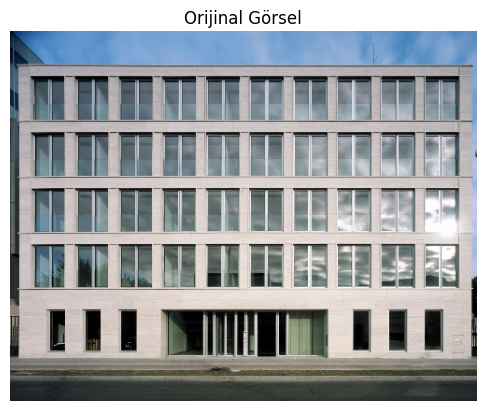

In [3]:
resim = cv2.imread("image09.jpeg")

# GPU üzerinde işlemeyi kolaylaştırmak için küçült
h, w = resim.shape[:2]

oran = min(1, 500 / max(h, w))

resim = cv2.resize(
    resim, None, fx=oran, fy=oran
)

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

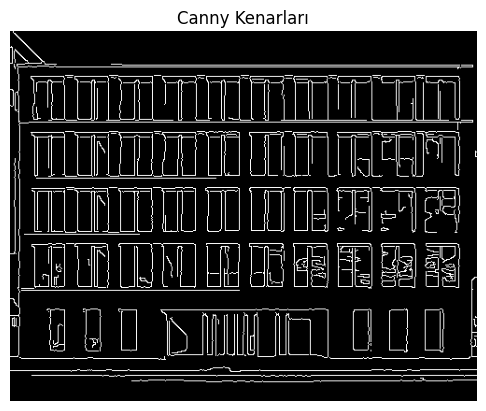

Kenar noktası sayısı: 19385


In [5]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

bulanik = cv2.GaussianBlur(gri, (5, 5), 1)

kenarlar = cv2.Canny(bulanik, 70, 170)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

ys, xs = np.where(kenarlar > 0)

xs = xs.astype(np.int32)
ys = ys.astype(np.int32)

print("Kenar noktası sayısı:", len(xs))

In [6]:
yukseklik, genislik = kenarlar.shape

max_rho = int(np.ceil(
    np.hypot(genislik, yukseklik)
))

# Açılar
acilar = np.deg2rad(
    np.arange(-90, 90)
).astype(np.float32)

# Sin ve cos tabloları
sin_tablosu = np.sin(acilar).astype(np.float32)
cos_tablosu = np.cos(acilar).astype(np.float32)

print("Açı sayısı:", len(acilar))
print("Maksimum rho:", max_rho)

Açı sayısı: 180
Maksimum rho: 638


In [7]:
@cuda.jit
def hough_cuda(xs, ys, cos_tab, sin_tab, oylama, max_rho):

    # Her GPU iş parçacığının indeksi
    i = cuda.grid(1)

    if i < xs.shape[0]:

        x = xs[i]
        y = ys[i]

        # Her açı için rho hesapla
        for t in range(cos_tab.shape[0]):

            rho = (
                x * cos_tab[t] +
                y * sin_tab[t]
            )

            rho_indeks = int(math.floor(rho + 0.5)) + max_rho

            if 0 <= rho_indeks < oylama.shape[0]:

                # Paralel ve güvenli oy artırma
                cuda.atomic.add(
                    oylama,
                    (rho_indeks, t),
                    1
                )

In [10]:
# Verileri GPU belleğine aktar
d_xs = cuda.to_device(xs)
d_ys = cuda.to_device(ys)

d_cos = cuda.to_device(cos_tablosu)
d_sin = cuda.to_device(sin_tablosu)

# Oylama matrisini oluştur
oylama = np.zeros(
    (2 * max_rho + 1, len(acilar)),
    dtype=np.int32
)

d_oylama = cuda.to_device(oylama)

# GPU ayarları
threads_per_block = 128

blocks_per_grid = (
    len(xs) + threads_per_block - 1
) // threads_per_block

# CUDA algoritmasını çalıştır
baslangic = time.perf_counter()

hough_cuda[blocks_per_grid, threads_per_block](
    d_xs,
    d_ys,
    d_cos,
    d_sin,
    d_oylama,
    max_rho
)

cuda.synchronize()

# Sonucu CPU belleğine al
oylama_gpu = d_oylama.copy_to_host()

gpu_sure = time.perf_counter() - baslangic

print("En yüksek oy:", oylama_gpu.max())
print("GPU süresi:", gpu_sure, "saniye")

En yüksek oy: 477
GPU süresi: 0.0014834859999837136 saniye


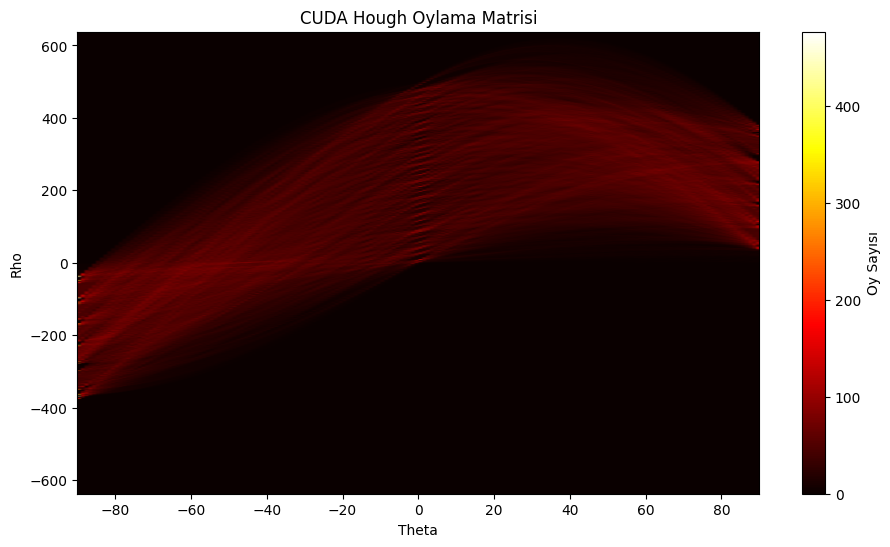

In [11]:
plt.figure(figsize=(11, 6))

plt.imshow(
    oylama_gpu,
    cmap="hot",
    aspect="auto",
    origin="lower",
    extent=[-90, 90, -max_rho, max_rho]
)

plt.title("CUDA Hough Oylama Matrisi")
plt.xlabel("Theta")
plt.ylabel("Rho")
plt.colorbar(label="Oy Sayısı")

plt.savefig("cuda_oylama_matrisi.png", dpi=200)
plt.show()

In [12]:
esik = max(30, int(oylama_gpu.max() * 0.45))

adaylar = np.argwhere(oylama_gpu >= esik)

adaylar = sorted(
    adaylar,
    key=lambda p: oylama_gpu[p[0], p[1]],
    reverse=True
)

secilenler = []

for r, t in adaylar:

    yakin = False

    for r2, t2 in secilenler:

        if abs(r-r2) <= 12 and abs(t-t2) <= 8:
            yakin = True
            break

    if not yakin:
        secilenler.append((r, t))

    if len(secilenler) >= 15:
        break

print("Eşik değeri:", esik)
print("Seçilen doğru sayısı:", len(secilenler))

Eşik değeri: 214
Seçilen doğru sayısı: 11


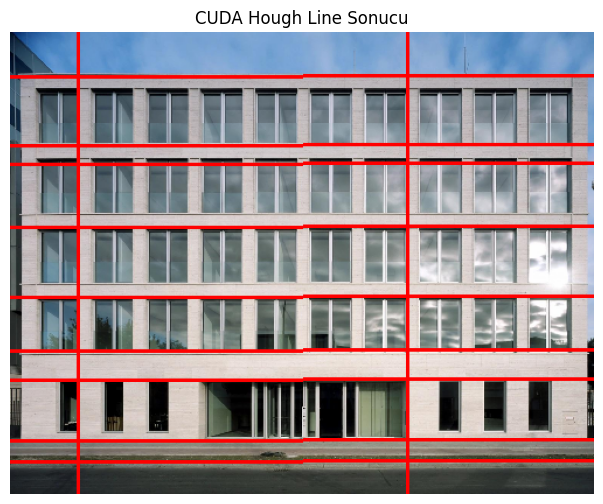

True

In [13]:
sonuc = resim.copy()

uzunluk = 2 * max_rho

for r, t in secilenler:

    rho = r - max_rho

    a = cos_tablosu[t]
    b = sin_tablosu[t]

    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + uzunluk * (-b))
    y1 = int(y0 + uzunluk * a)

    x2 = int(x0 - uzunluk * (-b))
    y2 = int(y0 - uzunluk * a)

    cv2.line(
        sonuc,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("CUDA Hough Line Sonucu")
plt.axis("off")
plt.show()

cv2.imwrite("cuda_hough_sonuc.png", sonuc)

In [14]:
oylama_cpu = np.zeros_like(oylama_gpu)

baslangic = time.perf_counter()

for t in range(len(acilar)):

    rho = (
        xs * cos_tablosu[t] +
        ys * sin_tablosu[t]
    )

    rho_indeks = (
        np.floor(rho + 0.5).astype(np.int32)
        + max_rho
    )

    np.add.at(
        oylama_cpu[:, t],
        rho_indeks,
        1
    )

cpu_sure = time.perf_counter() - baslangic

print("CPU süresi:", cpu_sure, "saniye")
print("GPU süresi:", gpu_sure, "saniye")

print("CPU toplam oy:", oylama_cpu.sum())
print("GPU toplam oy:", oylama_gpu.sum())

print(
    "Toplam oylar eşit mi?",
    oylama_cpu.sum() == oylama_gpu.sum()
)

print(
    "Farklı oylama hücresi sayısı:",
    np.count_nonzero(oylama_cpu != oylama_gpu)
)

CPU süresi: 0.40122304599998415 saniye
GPU süresi: 0.0014834859999837136 saniye
CPU toplam oy: 3489300
GPU toplam oy: 3489300
Toplam oylar eşit mi? True
Farklı oylama hücresi sayısı: 0
